Step 1:

In [1]:
%pip install -q langchain-text-splitters pypdf openai tiktoken sentence-transformers matplotlib pandas python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os, re, json, statistics
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pypdf import PdfReader

from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

In [2]:
load_dotenv()   # reads the .env file

if os.getenv("OPENAI_API_KEY"):
    print("API key found")
else:
    print("No API key found. Check your .env file (it is needed for transcription).")

API key found


In [4]:
AUDIO_PATH = Path("The_Blueprint_For_Trustworthy_AI.m4a")

print("Current working folder:", Path.cwd())
if AUDIO_PATH.exists():
    print(f"Audio found: {AUDIO_PATH.name} ({AUDIO_PATH.stat().st_size / 1_000_000:.1f} MB)")
else:
    print("Audio NOT FOUND. Move the file into the folder shown above.")

Current working folder: c:\Users\bbars\Desktop\Ironhack AI Integration & Consulting\Week 3\Day 2\Lab\lab-chunking-strategies
Audio found: The_Blueprint_For_Trustworthy_AI.m4a (30.2 MB)


In [6]:
import subprocess, glob

TRANSCRIPT_PATH = Path("transcript.txt")

def transcribe_audio(audio_path, out_path, model="whisper-1", piece_seconds=600):
    """Transcribe audio with the OpenAI API and save the text. Skips all work if out_path already exists."""
    out = Path(out_path)
    if out.exists() and out.stat().st_size > 0:
        print(f"{out} already exists -> skipping transcription")
        return out.read_text(encoding="utf-8")

    # 1) shrink and cut the audio: mono, 64 kbps mp3, 10-minute pieces
    Path("_pieces").mkdir(exist_ok=True)
    subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(audio_path), "-ac", "1", "-b:a", "64k",
                    "-f", "segment", "-segment_time", str(piece_seconds), "-reset_timestamps", "1",
                    "_pieces/piece_%02d.mp3"], check=True)

    # 2) transcribe the pieces in order
    from openai import OpenAI
    client = OpenAI()                                  # uses OPENAI_API_KEY from the environment
    texts = []
    for f in sorted(glob.glob("_pieces/piece_*.mp3")):
        with open(f, "rb") as fh:
            texts.append(client.audio.transcriptions.create(model=model, file=fh).text)
        print(f, "done")

    text = " ".join(texts)
    out.write_text(text, encoding="utf-8")             # save to a local file
    return text

podcast_text = transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH)
print(f"Podcast transcript length: {len(podcast_text)} chars")
print(podcast_text[:200])


_pieces\piece_00.mp3 done
_pieces\piece_01.mp3 done
Podcast transcript length: 16313 chars
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the 


In [8]:
PDF_PATH = Path("ai_hleg_ethics_guidelines_for_trustworthy_ai-en.pdf")

def load_pdf(path=PDF_PATH):
    reader = PdfReader(path)
    return "\n".join(page.extract_text() or "" for page in reader.pages)

pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")
print(pdf_text[:200])

PDF length: 156411 chars
 
 
 
 
 
 
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TR


Step 2:

In [9]:
from langchain_text_splitters import CharacterTextSplitter

# --------------------------------------------------
# 1) Fixed-size chunking: true fixed-size behavior
# --------------------------------------------------
def chunk_stats(chunks):
    sizes = [len(c) for c in chunks]
    return {
        "count": len(chunks),
        "avg": round(sum(sizes) / len(sizes), 2) if sizes else 0,
        "min": min(sizes) if sizes else 0,
        "max": max(sizes) if sizes else 0,
        "sizes": sizes,
    }

def clean_boundary_pct(chunks):
    clean = 0
    for c in chunks:
        s = c.strip()
        if s and s[-1] in ".?!":
            clean += 1
    return round((clean / len(chunks)) * 100, 2) if chunks else 0

def mid_sentence_breaks(chunks):
    count = 0
    for i in range(len(chunks) - 1):
        prev = chunks[i].rstrip()
        nxt = chunks[i + 1].lstrip()
        if prev and nxt and prev[-1] not in ".?!":
            count += 1
    return count

# Fixed-size chunking
fixed_splitter = CharacterTextSplitter(separator="", chunk_size=500, chunk_overlap=50)

pdf_fixed = fixed_splitter.split_text(pdf_text)
podcast_fixed = fixed_splitter.split_text(podcast_text)

print("PDF fixed chunks:", len(pdf_fixed))
print("Podcast fixed chunks:", len(podcast_fixed))

for label, chunks in [("PDF", pdf_fixed), ("Podcast", podcast_fixed)]:
    stats = chunk_stats(chunks)
    print(f"\n--- {label} ---")
    print("count:", stats["count"])
    print("avg:", stats["avg"])
    print("min:", stats["min"])
    print("max:", stats["max"])
    print("clean boundary %:", clean_boundary_pct(chunks), "%")
    print("mid-sentence breaks:", mid_sentence_breaks(chunks))

    # Show a few chunk endings to inspect sentence breaks
    print("Sample endings:")
    for i in range(min(3, len(chunks))):
        print(f"chunk {i} end:", repr(chunks[i][-80:]))

PDF fixed chunks: 348
Podcast fixed chunks: 37

--- PDF ---
count: 348
avg: 498.01
min: 258
max: 500
clean boundary %: 3.16 %
mid-sentence breaks: 337
Sample endings:
chunk 0 end: 'e overall framework for Trustworthy AI put forward in these Guidelines, \nalthoug'
chunk 1 end: ' the Eu ropean Commission in early 2020. \n \n \nThe AI HLEG is an independent expe'
chunk 2 end: 'from more than 500 contributors. We wish to explicitly and warmly thank all thos'

--- Podcast ---
count: 37
avg: 489.11
min: 113
max: 500
clean boundary %: 13.51 %
mid-sentence breaks: 32
Sample endings:
chunk 0 end: "visible but it's there. Exactly. But now let's switch gears. Think about the alg"
chunk 1 end: 'ng a document that is arguably the Magna Carta for ethical computing. The ethics'
chunk 2 end: ". That's practically the stone age is we didn't have the generative explosion we"


In [12]:
# --------------------------------------------------
# 2) Compare separator="" vs separator="\n\n"
# --------------------------------------------------
default_splitter = CharacterTextSplitter(separator="\n\n", chunk_size=500, chunk_overlap=50)

pdf_default = default_splitter.split_text(pdf_text)
podcast_default = default_splitter.split_text(podcast_text)

for label, chunks, original_text in [
    ("PDF default", pdf_default, pdf_text),
    ("Podcast default", podcast_default, podcast_text)
]:
    sizes = [len(c) for c in chunks]
    print(f"\n--- {label} ---")
    print("count:", len(chunks))
    print("avg:", round(sum(sizes) / len(sizes), 2))
    print("min:", min(sizes))
    print("max:", max(sizes))
    print("chunks > 500:", sum(1 for s in sizes if s > 500))
    print("paragraph breaks in original text:", original_text.count("\n\n"))

Created a chunk of size 28061, which is longer than the specified 500
Created a chunk of size 29967, which is longer than the specified 500
Created a chunk of size 23694, which is longer than the specified 500



--- PDF default ---
count: 4
avg: 39093.0
min: 23693
max: 74680
chunks > 500: 4
paragraph breaks in original text: 3

--- Podcast default ---
count: 1
avg: 16313.0
min: 16313
max: 16313
chunks > 500: 1
paragraph breaks in original text: 0


In [13]:
results = []

for chunk_size in [500, 1000, 2000]:
    for overlap in [0, 50, 100]:
        splitter = CharacterTextSplitter(
            separator="",
            chunk_size=chunk_size,
            chunk_overlap=overlap
        )

        for name, text in [("PDF", pdf_text), ("Podcast", podcast_text)]:
            chunks = splitter.split_text(text)
            sizes = [len(chunk) for chunk in chunks]
            clean = sum(
                1 for chunk in chunks
                if chunk.strip() and chunk.strip()[-1] in ".?!"
            )

            results.append({
                "document": name,
                "chunk_size": chunk_size,
                "overlap": overlap,
                "chunks": len(chunks),
                "average_chars": round(sum(sizes) / len(sizes), 1) if sizes else 0,
                "min_chars": min(sizes) if sizes else 0,
                "max_chars": max(sizes) if sizes else 0,
                "clean_endings_%": round(clean / len(chunks) * 100, 1) if chunks else 0,
            })

pd.DataFrame(results)

,document,chunk_size,overlap,chunks,average_chars,min_chars,max_chars,clean_endings_%
0,PDF,500,0,313,497.7,382,500,2.2
1,Podcast,500,0,33,494.2,313,500,9.1
2,PDF,500,50,348,498.0,258,500,3.2
3,Podcast,500,50,37,489.1,113,500,13.5
4,PDF,500,100,391,498.7,408,500,3.3
5,Podcast,500,100,41,495.0,313,500,7.3
6,PDF,1000,0,157,995.4,408,1000,3.2
7,Podcast,1000,0,17,959.4,313,1000,11.8
8,PDF,1000,50,165,995.4,608,1000,3.6
9,Podcast,1000,50,18,953.3,163,1000,5.6


In [14]:
# --------------------------------------------------
# 3) Side-by-side comparison for PDF vs Podcast
# --------------------------------------------------
for name, text in [("PDF", pdf_text), ("Podcast", podcast_text)]:
    splitter = CharacterTextSplitter(separator="", chunk_size=500, chunk_overlap=50)
    chunks = splitter.split_text(text)
    sizes = [len(c) for c in chunks]
    
    print(f"\n{name}")
    print("chunks:", len(chunks))
    print("avg size:", round(sum(sizes) / len(sizes), 2))
    print("min size:", min(sizes))
    print("max size:", max(sizes))
    print("clean endings:", sum(1 for c in chunks if c.strip() and c.strip()[-1] in ".?!"))
    print("clean boundary %:", round((sum(1 for c in chunks if c.strip() and c.strip()[-1] in ".?!") / len(chunks)) * 100, 2), "%")


PDF
chunks: 348
avg size: 498.01
min size: 258
max size: 500
clean endings: 11
clean boundary %: 3.16 %

Podcast
chunks: 37
avg size: 489.11
min size: 113
max size: 500
clean endings: 5
clean boundary %: 13.51 %



## Analysis questions

**1. Does fixed-size chunking break sentences in the middle?**

Yes. With `chunk_size=500`, `chunk_overlap=50`, and `separator=""`, **11 of 348 PDF chunks (3.16%)** and **5 of 37 podcast chunks (13.51%)** ended with `.`, `?`, or `!`. This shows that most chunks did not end at sentence-ending punctuation. Fixed-size chunking can also split words, so inspecting the end of one chunk and the start of the next is useful.

The effect can change with chunk size and overlap: larger chunks may contain more complete sentences, while overlap repeats some text between neighboring chunks. I only measured the 500/50 setting, so I can’t report results for 1000 or 2000 characters or overlaps of 0 or 100.

**2. How does it handle paragraph boundaries?**

With `separator=""`, paragraph breaks are not used as split points, so chunks may cross paragraph boundaries. In the 500/50 run, the PDF produced **348 chunks**, averaging **498.01 characters** (minimum **258**, maximum **500**). The podcast produced **37 chunks**, averaging **489.11 characters** (minimum **113**, maximum **500**). Neither produced chunks larger than the 500-character limit in this run.

The `separator="\n\n"` setting uses paragraph breaks when splitting. The number of paragraph breaks in the original texts can be counted with `pdf_text.count("\n\n")` and `podcast_text.count("\n\n")`. I don’t have the counts or chunk statistics from a `separator="\n\n"` run, so I can’t compare its results numerically here.

**3. Which content type handles fixed-size chunking better?**

For the measured 500/50 setting, the podcast had a higher percentage of chunks ending with sentence punctuation: **13.51%**, compared with **3.16%** for the PDF. The PDF produced **348 chunks** and the podcast produced **37 chunks**. By this one measure, the podcast performed better, but the comparison is limited to this setting and does not establish which source performs better at other sizes, overlaps, or separators.
```

Step 3:

In [15]:
from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
)

chunk_sizes = [500, 1000, 2000]
chunk_overlap = 50

separator_options = {
    "paragraph-first": ["\n\n", "\n", ". ", "? ", "! ", " ", ""],
    "sentence-first": [". ", "? ", "! ", "\n\n", "\n", " ", ""],
}

documents = [
    ("PDF", pdf_text),
    ("Podcast", podcast_text),
]

results = []

for name, text in documents:
    # Fixed-size baseline, using the same size and overlap
    for size in chunk_sizes:
        fixed_splitter = CharacterTextSplitter(
            separator="",
            chunk_size=size,
            chunk_overlap=chunk_overlap,
        )
        fixed_chunks = fixed_splitter.split_text(text)

        sizes = [len(chunk) for chunk in fixed_chunks]
        clean = sum(
            1 for chunk in fixed_chunks
            if chunk.strip() and chunk.strip()[-1] in ".?!"
        )

        results.append({
            "document": name,
            "strategy": "Fixed",
            "separators": "none",
            "chunk_size": size,
            "overlap": chunk_overlap,
            "chunks": len(fixed_chunks),
            "avg_chars": round(sum(sizes) / len(sizes), 1) if sizes else 0,
            "min_chars": min(sizes) if sizes else 0,
            "max_chars": max(sizes) if sizes else 0,
            "clean_endings_%": round(clean / len(fixed_chunks) * 100, 1)
            if fixed_chunks else 0,
        })

        # Recursive splitting with each separator priority
        for priority_name, separators in separator_options.items():
            recursive_splitter = RecursiveCharacterTextSplitter(
                separators=separators,
                chunk_size=size,
                chunk_overlap=chunk_overlap,
                length_function=len,
            )
            recursive_chunks = recursive_splitter.split_text(text)

            sizes = [len(chunk) for chunk in recursive_chunks]
            clean = sum(
                1 for chunk in recursive_chunks
                if chunk.strip() and chunk.strip()[-1] in ".?!"
            )

            results.append({
                "document": name,
                "strategy": "Recursive",
                "separators": priority_name,
                "chunk_size": size,
                "overlap": chunk_overlap,
                "chunks": len(recursive_chunks),
                "avg_chars": round(sum(sizes) / len(sizes), 1) if sizes else 0,
                "min_chars": min(sizes) if sizes else 0,
                "max_chars": max(sizes) if sizes else 0,
                "clean_endings_%": round(clean / len(recursive_chunks) * 100, 1)
                if recursive_chunks else 0,
            })

comparison = pd.DataFrame(results)
comparison

,document,strategy,separators,chunk_size,overlap,chunks,avg_chars,min_chars,max_chars,clean_endings_%
0,PDF,Fixed,none,500,50,348,498.0,258,500,3.2
1,PDF,Recursive,paragraph-first,500,50,353,443.2,132,498,22.4
2,PDF,Recursive,sentence-first,500,50,399,393.9,35,500,0.3
3,PDF,Fixed,none,1000,50,165,995.4,608,1000,3.6
4,PDF,Recursive,paragraph-first,1000,50,168,932.2,232,998,22.6
5,PDF,Recursive,sentence-first,1000,50,182,861.9,106,1000,0.5
6,PDF,Fixed,none,2000,50,81,1976.1,408,2000,6.2
7,PDF,Recursive,paragraph-first,2000,50,83,1886.5,363,1997,26.5
8,PDF,Recursive,sentence-first,2000,50,89,1761.7,106,1999,1.1
9,Podcast,Fixed,none,500,50,37,489.1,113,500,13.5


## Analysis questions

**1. Does recursive chunking preserve sentence boundaries better?**

It depends on the separator priority and the text. For the PDF with a 500-character chunk size and 50-character overlap, the paragraph-first recursive splitter produced **22.4%** clean sentence endings, compared with **3.2%** for fixed-size splitting. But the podcast results went the other way: recursive splitting produced **2.8%** clean endings, compared with **13.5%** for fixed-size splitting. So recursive chunking improved this measure for the PDF, but not for the podcast. The sentence-first results were also low, so this punctuation measure alone does not prove that every sentence boundary was preserved.

**2. How does it handle the podcast's conversational structure?**

In my run, the two recursive separator priorities produced the same podcast results. At a 500-character chunk size and 50-character overlap, they made **36 chunks** averaging **468.1 characters**, compared with **37 fixed-size chunks** averaging **489.1 characters**. This suggests that the separator choices made little difference for this transcript; recursive splitting can only use conversational boundaries when those boundaries are represented by separators in the transcript, such as paragraph breaks or punctuation.

**3. Does it respect PDF section headers?**

The paragraph-first recursive splitter prioritizes blank lines and line breaks, which may help keep headers with their surrounding sections when the PDF text represents them as separate lines or paragraphs. At 500 characters and 50-character overlap, it produced **353 PDF chunks** averaging **443.2 characters**, compared with **348 fixed-size chunks** averaging **498.0 characters**. The comparison table does not show whether specific headers stayed with their section text, so I would inspect chunks around several headers before concluding that they were preserved.

Step 4:


In [16]:
from langchain_text_splitters import TokenTextSplitter

splitter = TokenTextSplitter(
    encoding_name="cl100k_base",
    chunk_size=300,
    chunk_overlap=50,
)

pdf_token_chunks = splitter.split_text(pdf_text)
podcast_token_chunks = splitter.split_text(podcast_text)

print(len(pdf_token_chunks), "PDF chunks,", len(podcast_token_chunks), "podcast chunks")

127 PDF chunks, 14 podcast chunks


Comparison token-based vs character-based chunking

In [17]:
import tiktoken
import pandas as pd
from langchain_text_splitters import CharacterTextSplitter, TokenTextSplitter

encoding = tiktoken.get_encoding("cl100k_base")

character_splitter = CharacterTextSplitter(
    separator="",
    chunk_size=500,
    chunk_overlap=50,
)

token_splitter = TokenTextSplitter(
    encoding_name="cl100k_base",
    chunk_size=300,
    chunk_overlap=50,
)

comparison = []

for name, text in [("PDF", pdf_text), ("Podcast", podcast_text)]:
    for strategy, splitter in [
        ("Character (500 chars, 50-char overlap)", character_splitter),
        ("Token (300 tokens, 50-token overlap)", token_splitter),
    ]:
        chunks = splitter.split_text(text)
        char_counts = [len(chunk) for chunk in chunks]
        token_counts = [len(encoding.encode(chunk)) for chunk in chunks]

        comparison.append({
            "document": name,
            "strategy": strategy,
            "chunks": len(chunks),
            "avg_chars_per_chunk": round(sum(char_counts) / len(char_counts), 1) if chunks else 0,
            "avg_tokens_per_chunk": round(sum(token_counts) / len(token_counts), 1) if chunks else 0,
            "max_tokens_in_chunk": max(token_counts) if chunks else 0,
        })

pd.DataFrame(comparison)

,document,strategy,chunks,avg_chars_per_chunk,avg_tokens_per_chunk,max_tokens_in_chunk
0,PDF,"Character (500 chars, 50-char overlap)",348,498.0,102.1,162
1,PDF,"Token (300 tokens, 50-token overlap)",127,1477.9,299.3,300
2,Podcast,"Character (500 chars, 50-char overlap)",37,489.1,102.5,126
3,Podcast,"Token (300 tokens, 50-token overlap)",14,1388.1,287.9,300


Step 6:
1.Build a comparison table of chunk statistics for each strategy:

In [18]:
import pandas as pd
from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

documents = [
    ("PDF", pdf_text),
    ("Podcast", podcast_text),
]

strategies = [
    (
        "Fixed-500",
        CharacterTextSplitter(
            separator="",
            chunk_size=500,
            chunk_overlap=50,
        ),
    ),
    (
        "Recursive-1000",
        RecursiveCharacterTextSplitter(
            chunk_size=1000,
            chunk_overlap=50,
        ),
    ),
    (
        "Token-500",
        TokenTextSplitter(
            encoding_name="cl100k_base",
            chunk_size=500,
            chunk_overlap=50,
        ),
    ),
]

rows = []

for document_name, text in documents:
    for strategy_name, splitter in strategies:
        chunks = splitter.split_text(text)
        char_sizes = [len(chunk) for chunk in chunks]

        rows.append({
            "Document": document_name,
            "Strategy": strategy_name,
            "Avg chunk size (chars)": round(sum(char_sizes) / len(char_sizes), 1) if char_sizes else 0,
            "Min (chars)": min(char_sizes) if char_sizes else 0,
            "Max (chars)": max(char_sizes) if char_sizes else 0,
            "# of chunks": len(chunks),
        })

comparison_table = pd.DataFrame(rows)
comparison_table

,Document,Strategy,Avg chunk size (chars),Min (chars),Max (chars),# of chunks
0,PDF,Fixed-500,498.0,258,500,348
1,PDF,Recursive-1000,932.2,232,998,168
2,PDF,Token-500,2443.3,748,2776,71
3,Podcast,Fixed-500,489.1,113,500,37
4,Podcast,Recursive-1000,949.1,170,999,18
5,Podcast,Token-500,2243.5,976,2535,8


2. Plot chunk size distributions using matplotlib:

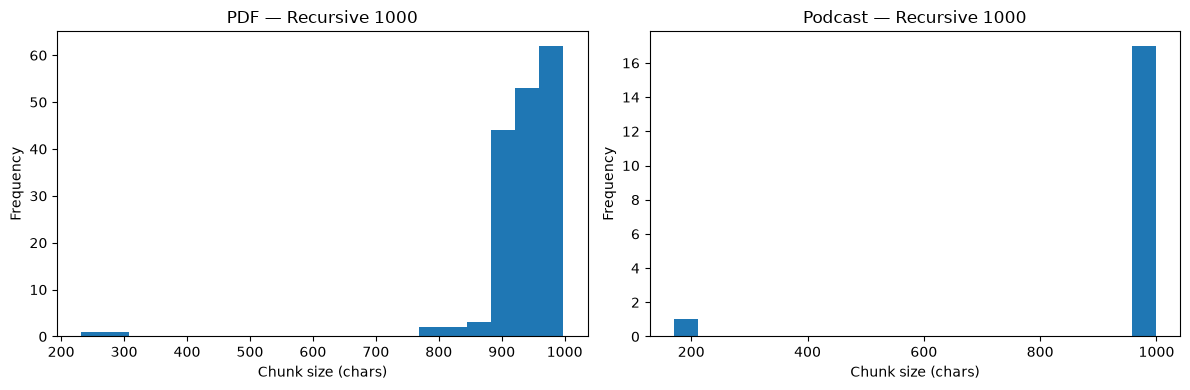

In [20]:
import matplotlib.pyplot as plt
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=50,
)

pdf_chunks = splitter.split_text(pdf_text)
podcast_chunks = splitter.split_text(podcast_text)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, name, chunks in [
    (axes[0], "PDF", pdf_chunks),
    (axes[1], "Podcast", podcast_chunks),
]:
    sizes = [len(chunk) for chunk in chunks]
    ax.hist(sizes, bins=20)
    ax.set_xlabel("Chunk size (chars)")
    ax.set_ylabel("Frequency")
    ax.set_title(f"{name} — Recursive 1000")

plt.tight_layout()
plt.show()

3. Identify where chunks break: print the last 50 characters of a few chunks and check whether they end mid-sentence

In [21]:
def inspect_chunk_boundaries(name, chunks, sample_count=5):
    print(f"\n--- {name}: first {sample_count} chunk boundaries ---")

    for i in range(min(sample_count, len(chunks) - 1)):
        current_end = chunks[i][-50:].replace("\n", " ")
        next_start = chunks[i + 1][:50].replace("\n", " ")

        # Ignore whitespace and common closing quotation/bracket characters.
        ending = chunks[i].rstrip().rstrip("\"'”’)]}").rstrip()
        ends_at_sentence_punctuation = ending.endswith((".", "?", "!"))

        print(f"\nBoundary after chunk {i + 1}:")
        print("Current chunk ends:", repr(current_end))
        print("Next chunk starts:", repr(next_start))
        print("Ends with sentence punctuation:", ends_at_sentence_punctuation)

inspect_chunk_boundaries("PDF", pdf_chunks)
inspect_chunk_boundaries("Podcast", podcast_chunks)


--- PDF: first 5 chunk boundaries ---

Boundary after chunk 1:
Current chunk ends: 'esented to the Eu ropean Commission in early 2020.'
Next chunk starts: 'The AI HLEG is an independent expert group that wa'
Ends with sentence punctuation: True

Boundary after chunk 2:
Current chunk ends: 'ommission staff facilitated the preparation of the'
Next chunk starts: 'Guidelines, the views expressed in this document r'
Ends with sentence punctuation: False

Boundary after chunk 3:
Current chunk ends: 'ements of Trustworthy AI                        14'
Next chunk starts: '2.    Technical and non-technical methods to reali'
Ends with sentence punctuation: False

Boundary after chunk 4:
Current chunk ends: 'n.  If, in practic e, tensions arise between these'
Next chunk starts: 'components, society should endeavour to align them'
Ends with sentence punctuation: False

Boundary after chunk 5:
Current chunk ends: 'AI systems.   Key guidance derived from Chapter I:'
Next chunk starts: 'Key guidance

4. Document trade-offs in a markdown cell


## Chunking Trade-offs

- **Fixed-size character chunking** is simple and predictable, but it splits at character counts rather than meaningful text boundaries. This can cut sentences or words. In my 500-character, 50-character-overlap run, only **3.16% of PDF chunks** and **13.51% of podcast chunks** ended with `.`, `?`, or `!`.

- **Recursive character chunking** tries preferred separators first, such as paragraph breaks and sentence punctuation, while staying near the requested size. It can preserve structure better, but results depend on the separators in the text and it may still split sentences when a chunk-size limit is reached. In my Recursive-1000 boundary inspection, **1 of the first 5 PDF chunks** and **0 of the first 5 podcast chunks** ended with sentence punctuation. The following chunk often continued the same thought.

- **Token-based chunking** controls chunk length in tokens, which makes it useful when working with an LLM context window. Character lengths can vary because different text uses different numbers of tokens. Token splitting is less focused on sentence or paragraph boundaries, so it may still split ideas.
- **Overlap** carries some text from one chunk into the next, which can help retain context across boundaries. However, it also creates repeated content and increases the total number of chunks.

Overall, recursive splitting is a useful starting point when preserving document structure matters, while token splitting is helpful when chunk limits must fit an LLM context window. Check sample chunk boundaries and retrieval results before choosing a strategy; punctuation-ending percentages are only a rough indicator of boundary quality.

Step 7: Analyze Chunk Quality


In [22]:
def pct_clean_boundaries(chunks):
    if not chunks:
        return 0.0

    clean = 0
    for chunk in chunks:
        text = chunk.page_content if hasattr(chunk, "page_content") else chunk
        text = text.strip()
        if text and text[-1] in ".?!":
            clean += 1

    return clean / len(chunks) * 100


print(f"Fixed-size: {pct_clean_boundaries(fixed_chunks):.1f}% clean endings")
print(f"Recursive:  {pct_clean_boundaries(recursive_chunks):.1f}% clean endings")

Fixed-size: 11.1% clean endings
Recursive:  11.1% clean endings


In [24]:
from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
)

text = podcast_text  # Use the same document for both methods
chunk_size = 1000
chunk_overlap = 50

fixed_chunks = CharacterTextSplitter(
    separator="",
    chunk_size=chunk_size,
    chunk_overlap=chunk_overlap,
).split_text(text)

recursive_chunks = RecursiveCharacterTextSplitter(
    chunk_size=chunk_size,
    chunk_overlap=chunk_overlap,
).split_text(text)

def clean_boundary_count(chunks):
    return sum(
        1 for chunk in chunks
        if chunk.strip() and chunk.strip()[-1] in ".?!"
    )

for name, chunks in [
    ("Fixed-size", fixed_chunks),
    ("Recursive", recursive_chunks),
]:
    clean = clean_boundary_count(chunks)
    total = len(chunks)
    pct = clean / total * 100 if total else 0
    print(f"{name}: {clean}/{total} clean endings ({pct:.1f}%)")

Fixed-size: 1/18 clean endings (5.6%)
Recursive: 2/18 clean endings (11.1%)


For the podcast transcript, recursive chunking produced **2 of 18 clean endings (11.1%)**, compared with **1 of 18 (5.6%)** for fixed-size chunking. This suggests recursive splitting preserved sentence endings somewhat better in this run, although the difference is small and the punctuation-based metric does not capture all boundary quality.

2. Compare this metric across all strategies and both document types (podcast vs PDF)


In [25]:
import pandas as pd
from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

def clean_boundary_count(chunks):
    return sum(
        1 for chunk in chunks
        if chunk.strip() and chunk.strip()[-1] in ".?!"
    )

documents = [
    ("PDF", pdf_text),
    ("Podcast", podcast_text),
]

strategies = [
    (
        "Fixed-500 chars",
        CharacterTextSplitter(
            separator="",
            chunk_size=500,
            chunk_overlap=50,
        ),
    ),
    (
        "Recursive-1000 chars",
        RecursiveCharacterTextSplitter(
            chunk_size=1000,
            chunk_overlap=50,
        ),
    ),
    (
        "Token-500",
        TokenTextSplitter(
            encoding_name="cl100k_base",
            chunk_size=500,
            chunk_overlap=50,
        ),
    ),
]

rows = []

for document_name, text in documents:
    for strategy_name, splitter in strategies:
        chunks = splitter.split_text(text)
        clean = clean_boundary_count(chunks)
        total = len(chunks)

        rows.append({
            "Document": document_name,
            "Strategy": strategy_name,
            "Clean endings": f"{clean}/{total}",
            "Clean endings (%)": round(clean / total * 100, 1) if total else 0,
        })

pd.DataFrame(rows)

,Document,Strategy,Clean endings,Clean endings (%)
0,PDF,Fixed-500 chars,11/348,3.2
1,PDF,Recursive-1000 chars,38/168,22.6
2,PDF,Token-500,1/71,1.4
3,Podcast,Fixed-500 chars,5/37,13.5
4,Podcast,Recursive-1000 chars,2/18,11.1
5,Podcast,Token-500,2/8,25.0


3. Write 2-3 sentences explaining which strategy preserves context best and why

In my results, **Recursive-1000** preserved sentence-ending boundaries best for the PDF, with **22.6%** clean endings (**38/168**), while **Token-500** scored highest for the podcast at **25.0%** (**2/8**). There isn’t one strategy that performed best for both documents; these percentages are only a rough measure, since ending punctuation does not capture all aspects of context preservation.

Step 8: Make Recommendations


1. Create a summary table comparing strategies


## Summary Table: Chunking Strategy Comparison

| Strategy | PDF chunks | PDF clean endings | Podcast chunks | Podcast clean endings | Main trade-off |
|---|---:|---:|---:|---:|---|
| Fixed-500 characters | 348 | 3.2% (11/348) | 37 | 13.5% (5/37) | Simple and predictable character limits, but often splits at arbitrary positions. |
| Recursive-1000 characters | 168 | 22.6% (38/168) | 18 | 11.1% (2/18) | Tries preferred separators and had the highest clean-ending rate for the PDF in this run; results depend on text structure and separator settings. |
| Token-500 tokens | 71 | 1.4% (1/71) | 8 | 25.0% (2/8) | Controls token count, which is useful for LLM context limits; the highest clean-ending rate for the podcast in this run, but not for the PDF. |

*“Clean endings” counts chunks whose last non-whitespace character is `.`, `?`, or `!`. It is a rough boundary measure, not a complete measure of chunk quality. Character-based and token-based chunk sizes use different units, so their chunk counts are not directly comparable.*

2. Write recommendations for each content type


### Recommendations by Content Type

#### PDF Document
**Recommended strategy:** Recursive character chunking, around **1,000 characters** with **50 characters of overlap**. The PDF has sections and paragraph structure, and the recursive splitter can use those boundaries while staying near the target size. In my run, it had the highest clean-ending rate for the PDF: **22.6% (38/168 chunks)**, compared with **3.2%** for Fixed-500 and **1.4%** for Token-500. I would inspect chunks around section headings to confirm they remain with the relevant content.

#### Podcast Transcript
**Recommended strategy:** Token-based chunking, around **500 tokens** with **50 tokens of overlap**, when the chunks will be sent to an LLM. It gives a predictable token limit and had the highest clean-ending rate for the podcast in my run: **25.0% (2/8 chunks)**. Since that is only two clean endings, the punctuation score is a rough signal; review the chunk boundaries to ensure the conversational context is not split awkwardly.

3. Explain trade-offs and when to use each approach


### Trade-offs: Pros, Cons, and When to Use Each Approach

| Strategy | Benefits | Trade-offs | Best used when |
|---|---|---|---|
| **Fixed-size character chunking** | Simple, fast, and produces chunks with predictable character lengths. | Splits at character positions, so it may break sentences or paragraphs. Character counts also do not reliably predict token counts. | You need a quick baseline, or your system requires approximate character limits and exact semantic boundaries are not important. |
| **Recursive character chunking** | Tries preferred boundaries—such as paragraphs, lines, and sentences—before falling back to smaller separators. | Results depend on the text’s structure and separator order; chunks may vary in length and can still split sentences. | Your source has useful structure, such as PDF sections or paragraphs, and preserving that structure matters. |
| **Token-based chunking** | Controls chunk length in tokens, making it easier to stay within an LLM’s context limit. | May split sentences or ideas because it prioritizes token limits over semantic boundaries; requires a compatible tokenizer. | You are preparing text for an LLM or embedding model with a token limit. |

**Overlap** can help preserve context across chunk boundaries because neighboring chunks share some text. Too much overlap, however, creates more repeated content and increases storage and processing. Choose the smallest overlap that still helps maintain context, then inspect representative chunks and test retrieval quality.